In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
from statsmodels.tsa.statespace.sarimax import SARIMAX

SEED = 42
np.random.seed(SEED)

DATA_PATH = "cleaned_station_temperature.csv"
OUT_DIR   = "ml_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Time-based split: never shuffle time series data
TRAIN_END = pd.Timestamp("2022-12-31")   # train      : start .. 2022
VAL_END   = pd.Timestamp("2024-12-31")   # validation : 2023 .. 2024  (used to tune models)
                                          # test       : 2025 .. Aug 2026 (touched only once, at the end)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df["Hemisphere"] = df["Hemisphere"].str.strip()      # guards against hidden \r from Windows line endings
print(df.shape, "|", df["Station_ID"].nunique(), "stations |", df["Date"].min().date(), "to", df["Date"].max().date())
print("Missing values:\n", df.isna().sum()[lambda s: s > 0])
print("Hemisphere values:", df["Hemisphere"].unique())

# Proof of the leakage: the rolling column contains the current month's value
chk = df[df.Station_ID == df.Station_ID.iloc[0]].head(3)[["Date", "Average_Temperature_C", "Rolling_3M_Avg_C"]]
display(chk)

# Hemisphere-aware seasons
def season_corrected(month, hemi):
    north = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
             6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
    flip  = {"Winter":"Summer","Summer":"Winter","Spring":"Autumn","Autumn":"Spring"}
    s = north[month]
    return s if hemi == "Northern" else flip[s]
df["Season_Corrected"] = [season_corrected(m, h) for m, h in zip(df["Month"], df["Hemisphere"])]

def climate_zone(lat):
    a = abs(lat)
    return "1 Tropical" if a < 23.5 else "2 Subtropical" if a < 35 else "3 Temperate" if a < 55 else "4 Polar/Subpolar"
df["Climate_Zone"] = df["Latitude"].apply(climate_zone)

(50000, 16) | 250 stations | 2000-12-01 to 2026-08-01
Missing values:
 Elevation_m    200
dtype: int64
Hemisphere values: <StringArray>
['Northern', 'Southern']
Length: 2, dtype: str


,Date,Average_Temperature_C,Rolling_3M_Avg_C
0,2007-04-01,29.10,29.10
1,2007-05-01,32.68,30.89
2,2007-06-01,33.68,31.82


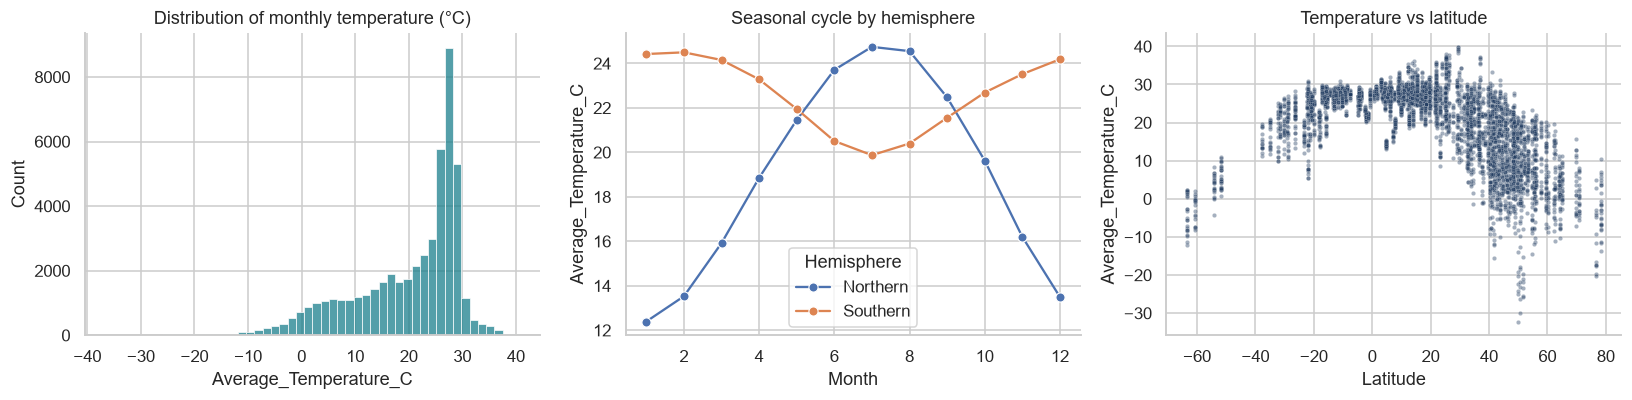

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df["Average_Temperature_C"], bins=50, ax=ax[0], color="#1B7F8C"); ax[0].set_title("Distribution of monthly temperature (°C)")
m = df.groupby(["Hemisphere", "Month"])["Average_Temperature_C"].mean().reset_index()
sns.lineplot(data=m, x="Month", y="Average_Temperature_C", hue="Hemisphere", marker="o", ax=ax[1]); ax[1].set_title("Seasonal cycle by hemisphere")
sns.scatterplot(data=df.sample(5000, random_state=SEED), x="Latitude", y="Average_Temperature_C", s=8, alpha=.4, ax=ax[2], color="#1F3A5F"); ax[2].set_title("Temperature vs latitude")
plt.tight_layout(); plt.show()

In [4]:
df["t"] = df["Year"] * 12 + df["Month"]                      # integer month index so lags respect calendar gaps
df = df.sort_values(["Station_ID", "t"]).reset_index(drop=True)
assert not df.duplicated(["Station_ID", "t"]).any()

# 1) Climatology from TRAINING years only
train_rows = df["Date"] <= TRAIN_END
clim = df[train_rows].groupby(["Station_ID", "Month"])["Average_Temperature_C"].mean().rename("clim")
df = df.join(clim, on=["Station_ID", "Month"])
st_mean = df[train_rows].groupby("Station_ID")["Average_Temperature_C"].mean()
df["clim"] = df["clim"].fillna(df["Station_ID"].map(st_mean))       # fallback: station mean
print("Rows with no climatology (station has no training data):", df["clim"].isna().sum())
df = df.dropna(subset=["clim"]).reset_index(drop=True)
df["anom"] = df["Average_Temperature_C"] - df["clim"]

# 2) Lag features by calendar month (a gap in the record gives NaN, not a wrong value)
key     = pd.MultiIndex.from_arrays([df["Station_ID"], df["t"]])
s_anom  = pd.Series(df["anom"].values, index=key)
s_temp  = pd.Series(df["Average_Temperature_C"].values, index=key)
def lagged(series, L):
    return series.reindex(pd.MultiIndex.from_arrays([df["Station_ID"], df["t"] - L])).values

for L in range(1, 13):
    df[f"anom_lag{L}"] = lagged(s_anom, L)
df["temp_lag1"]  = lagged(s_temp, 1)      # raw lags: used ONLY by the baselines
df["temp_lag12"] = lagged(s_temp, 12)

lag3  = df[["anom_lag1", "anom_lag2", "anom_lag3"]]
lag12 = df[[f"anom_lag{L}" for L in range(1, 13)]]
df["anom_roll3"]  = lag3.mean(axis=1).where(lag3.notna().sum(axis=1) >= 2)
df["anom_roll12"] = lag12.mean(axis=1).where(lag12.notna().sum(axis=1) >= 6)

# 3) Calendar / location features
df["trend_t"]  = df["Year"] + (df["Month"] - 1) / 12 - 2000
df["is_north"] = (df["Hemisphere"] == "Northern").astype(int)
df["Elevation_m"] = df["Elevation_m"].fillna(df["Elevation_m"].median())

FEATURES = ["anom_lag1", "anom_lag2", "anom_lag3", "anom_lag12", "anom_roll3", "anom_roll12",
            "Month_Sin", "Month_Cos", "trend_t", "Latitude", "Longitude", "Elevation_m", "is_north", "clim"]
FILL0 = ["anom_lag2", "anom_lag3", "anom_roll3", "anom_roll12"]      # missing anomaly = "normal" (0)
df[FILL0] = df[FILL0].fillna(0)

# 4) Rows we can model: need last month AND same month last year
model_df = df.dropna(subset=["anom_lag1", "anom_lag12"]).copy()
print(f"Modelling rows: {len(model_df):,} of {len(df):,} ({len(model_df)/len(df):.1%})")

Rows with no climatology (station has no training data): 0
Modelling rows: 43,400 of 50,000 (86.8%)


In [5]:
tr = model_df[model_df["Date"] <= TRAIN_END]
va = model_df[(model_df["Date"] > TRAIN_END) & (model_df["Date"] <= VAL_END)]
te = model_df[model_df["Date"] > VAL_END].copy()
trva = pd.concat([tr, va])

for name, part in [("Train", tr), ("Validation", va), ("Test", te)]:
    print(f"{name:11s} {len(part):6,d} rows   {part.Date.min():%Y-%m} to {part.Date.max():%Y-%m}   {part.Station_ID.nunique()} stations")

X_tr, y_tr   = tr[FEATURES],   tr["anom"]
X_va, y_va   = va[FEATURES],   va["anom"]
X_te         = te[FEATURES]
X_trva, y_trva = trva[FEATURES], trva["anom"]

Train       34,614 rows   2001-12 to 2022-12   250 stations
Validation   5,242 rows   2023-01 to 2024-12   243 stations
Test         3,544 rows   2025-01 to 2026-08   238 stations


In [6]:
def evaluate(frame, pred_temp):
    y = frame["Average_Temperature_C"].values
    p = np.asarray(pred_temp)
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p),
            "Anomaly_R2": r2_score(frame["anom"].values, p - frame["clim"].values)}

results, preds_test = {}, {}
def record(name, mtype, pred_temp, frame=None):
    frame = te if frame is None else frame
    results[name] = {"Model_Type": mtype, "n_test": len(frame), **evaluate(frame, pred_temp)}
    preds_test[name] = pd.Series(np.asarray(pred_temp), index=frame.index)

In [7]:
record("Persistence (last month)",              "Baseline", te["temp_lag1"])
record("Seasonal Naive (same month last year)", "Baseline", te["temp_lag12"])
record("Station-Month Climatology",             "Baseline", te["clim"])
pd.DataFrame(results).T[["MAE", "RMSE", "R2", "Anomaly_R2"]].round(3)

,MAE,RMSE,R2,Anomaly_R2
Persistence (last month),2.081905,3.113327,0.915832,-5.520672
Seasonal Naive (same month last year),1.182988,1.75223,0.973339,-1.065501
Station-Month Climatology,0.93571,1.309272,0.985115,-0.153195


In [8]:
def fit_select(make_model, grid, name):
    """Pick the setting with the lowest validation MAE (on temperature), then refit on train+val."""
    rows = []
    for g in grid:
        m = make_model(**g).fit(X_tr, y_tr)
        p = va["clim"] + m.predict(X_va)
        rows.append({**g, "val_MAE": mean_absolute_error(va["Average_Temperature_C"], p)})
    tune = pd.DataFrame(rows).sort_values("val_MAE")
    best = {k: tune.iloc[0][k] for k in grid[0]}
    best = {k: (int(v) if isinstance(grid[0][k], int) else float(v)) for k, v in best.items()}
    display(Markdown(f"**{name}: validation results**")); display(tune.round(4).reset_index(drop=True))
    final = make_model(**best).fit(X_trva, y_trva)
    return final, best

ridge, best = fit_select(lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
                         [{"alpha": a} for a in [0.01, 0.1, 1, 10, 100, 1000]], "Ridge")
record("Ridge Regression", "Linear", te["clim"] + ridge.predict(X_te))
print("Chosen:", best)
print(pd.Series(ridge[-1].coef_, index=FEATURES).round(3).sort_values(key=abs, ascending=False).head(6).to_string())

**Ridge: validation results**

,alpha,val_MAE
0,0.01,0.8392
1,0.10,0.8392
2,1.00,0.8392
3,10.00,0.8392
4,100.00,0.8393
5,1000.00,0.8404


Chosen: {'alpha': 0.01}
anom_lag1     0.330
trend_t       0.186
anom_roll3   -0.148
anom_lag3     0.129
anom_lag12   -0.095
anom_lag2     0.095


In [9]:
rf, best = fit_select(lambda n_estimators, min_samples_leaf, max_features:
                          RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                                                max_features=max_features, n_jobs=-1, random_state=SEED),
                      [{"n_estimators": 300, "min_samples_leaf": l, "max_features": f}
                       for l in (3, 8, 20) for f in (0.4, 0.7)], "Random Forest")
record("Random Forest", "Bagging", te["clim"] + rf.predict(X_te))
print("Chosen:", best)

**Random Forest: validation results**

,n_estimators,min_samples_leaf,max_features,val_MAE
0,300,20,0.4,0.8456
1,300,8,0.4,0.8474
2,300,20,0.7,0.8524
3,300,8,0.7,0.8534
4,300,3,0.4,0.8543
5,300,3,0.7,0.8603


Chosen: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.4}


In [10]:
xgb_params = dict(learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, reg_lambda=5, tree_method="hist", n_jobs=2, random_state=SEED)
xgb_es = xgb.XGBRegressor(n_estimators=3000, early_stopping_rounds=100, **xgb_params)
xgb_es.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
best_n = xgb_es.best_iteration + 1
print("Best number of trees:", best_n, "| validation RMSE (anomaly):", round(xgb_es.best_score, 4))

xgb_final = xgb.XGBRegressor(n_estimators=best_n, **xgb_params).fit(X_trva, y_trva)
record("XGBoost", "Boosting", te["clim"] + xgb_final.predict(X_te))

Best number of trees: 147 | validation RMSE (anomaly): 1.2463


In [11]:
lgb_params = dict(learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=5, n_jobs=2, random_state=SEED, verbose=-1)
lgb_es = lgb.LGBMRegressor(n_estimators=3000, **lgb_params)
lgb_es.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
best_n = lgb_es.best_iteration_
print("Best number of trees:", best_n)

lgb_final = lgb.LGBMRegressor(n_estimators=best_n, **lgb_params).fit(X_trva, y_trva)
record("LightGBM", "Boosting", te["clim"] + lgb_final.predict(X_te))

Best number of trees: 149


In [12]:
df["Station_Name"] = df["Station_Name"].str.replace("*", "", regex=False).str.strip()
stn = (df.groupby("Station_ID").agg(Latitude=("Latitude", "first"), Hemisphere=("Hemisphere", "first"),
                                    Climate_Zone=("Climate_Zone", "first"), Name=("Station_Name", "first")))
test_counts = te.groupby("Station_ID").size().rename("test_rows")
cand = stn.join(test_counts).dropna(subset=["test_rows"])
cand = cand[cand["test_rows"] >= 12]
sarima_stations = (cand.sort_values("test_rows", ascending=False)
                       .groupby(["Climate_Zone", "Hemisphere"]).head(1))
display(sarima_stations[["Name", "Climate_Zone", "Hemisphere", "Latitude", "test_rows"]])

,Name,Climate_Zone,Hemisphere,Latitude,test_rows
Station_ID,,,,,
AG000060390,ALGER_DAR_EL_BEIDA,3 Temperate,Northern,36.7167,20.0
AQW00061705,PAGO_PAGO_WSO_AP,1 Tropical,Southern,-14.3306,20.0
AYM00088963,BASE_ESPERANZA,4 Polar/Subpolar,Southern,-63.4000,20.0
ASM00094995,LORD_HOWE_ISLAND_AERO,2 Subtropical,Southern,-31.5420,20.0
CJW00011813,ROBERTS,1 Tropical,Northern,19.3000,20.0
BA000041150,BAHRAIN_INT_AIRPO,2 Subtropical,Northern,26.2670,20.0
BOM00026554,VERHNEDVINSK,4 Polar/Subpolar,Northern,55.8170,20.0
FKM00088889,MOUNT_PLEASANT,3 Temperate,Southern,-51.8230,20.0


In [13]:
TEST_START = VAL_END + pd.Timedelta(days=1)
sar_frames = []
for sid in sarima_stations.index:
    s = df[df["Station_ID"] == sid].set_index("Date")["Average_Temperature_C"]
    full = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="MS")).interpolate(limit_area="inside")
    fit_part = full[:VAL_END]
    res = SARIMAX(fit_part, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12),
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
    one_step = res.apply(full, refit=False).get_prediction(start=TEST_START, dynamic=False).predicted_mean
    sar_frames.append(pd.DataFrame({"Station_ID": sid, "Date": one_step.index, "pred": one_step.values}))
sar = pd.concat(sar_frames)

# score only on real observed test months that the ML models were also scored on
te_sar = te.reset_index().merge(sar, on=["Station_ID", "Date"], how="inner").set_index("index")
record("SARIMA", "Time-series", te_sar["pred"], frame=te_sar)
print(f"SARIMA scored on {te_sar['Station_ID'].nunique()} stations, {len(te_sar)} test months")

SARIMA scored on 8 stations, 160 test months


In [28]:
order = ["Persistence (last month)", "Seasonal Naive (same month last year)", "Station-Month Climatology",
         "Ridge Regression", "Random Forest", "XGBoost", "LightGBM", "SARIMA"]
comp = pd.DataFrame(results).T.loc[order]
for c in ["MAE", "RMSE", "R2", "Anomaly_R2"]: comp[c] = comp[c].astype(float)
comp["MAE_gain_vs_best_baseline_%"] = ((comp.loc[comp.Model_Type == "Baseline", "MAE"].min() - comp["MAE"])
                                       / comp.loc[comp.Model_Type == "Baseline", "MAE"].min() * 100)
comp.loc["SARIMA", "MAE_gain_vs_best_baseline_%"] = np.nan      # scored on a subset only: see table B
print(f"A. FULL TEST SET  ({len(te):,} station-months; SARIMA row uses {len(te_sar)} station-months)")
display(comp[["Model_Type", "MAE", "RMSE", "R2", "Anomaly_R2", "MAE_gain_vs_best_baseline_%"]].round(3)
        .style.highlight_min(subset=["MAE", "RMSE"], color="#c8ead9").highlight_max(subset=["R2", "Anomaly_R2"], color="#c8ead9"))

same = []
for name in order:
    p = preds_test[name].reindex(te_sar.index) if name != "SARIMA" else te_sar["pred"]
    same.append({"Model": name, **evaluate(te_sar, p.values)})
same = pd.DataFrame(same).set_index("Model")
print(f"\nB. SAME-STATIONS COMPARISON  ({len(te_sar)} station-months, {te_sar.Station_ID.nunique()} stations)")
display(same.round(3).style.highlight_min(subset=["MAE", "RMSE"], color="#c8ead9").highlight_max(subset=["R2", "Anomaly_R2"], color="#c8ead9"))

A. FULL TEST SET  (3,544 station-months; SARIMA row uses 160 station-months)


,Model_Type,MAE,RMSE,R2,Anomaly_R2,MAE_gain_vs_best_baseline_%
Persistence (last month),Baseline,2.082000,3.113000,0.916000,-5.521000,-122.495000
Seasonal Naive (same month last year),Baseline,1.183000,1.752000,0.973000,-1.066000,-26.427000
Station-Month Climatology,Baseline,0.936000,1.309000,0.985000,-0.153000,0.000000
Ridge Regression,Linear,0.818000,1.192000,0.988000,0.044000,12.535000
Random Forest,Bagging,0.807000,1.196000,0.988000,0.038000,13.713000
XGBoost,Boosting,0.813000,1.199000,0.988000,0.032000,13.134000
LightGBM,Boosting,0.815000,1.206000,0.987000,0.021000,12.946000
SARIMA,Time-series,1.106000,1.702000,0.980000,-0.042000,nan



B. SAME-STATIONS COMPARISON  (160 station-months, 8 stations)


,MAE,RMSE,R2,Anomaly_R2
Model,,,,
Persistence (last month),2.046000,3.045000,0.937000,-2.334000
Seasonal Naive (same month last year),1.365000,2.151000,0.968000,-0.664000
Station-Month Climatology,1.187000,1.751000,0.979000,-0.103000
Ridge Regression,1.076000,1.626000,0.982000,0.049000
Random Forest,1.057000,1.634000,0.982000,0.040000
XGBoost,1.098000,1.671000,0.981000,-0.004000
LightGBM,1.083000,1.661000,0.981000,0.008000
SARIMA,1.106000,1.702000,0.980000,-0.042000


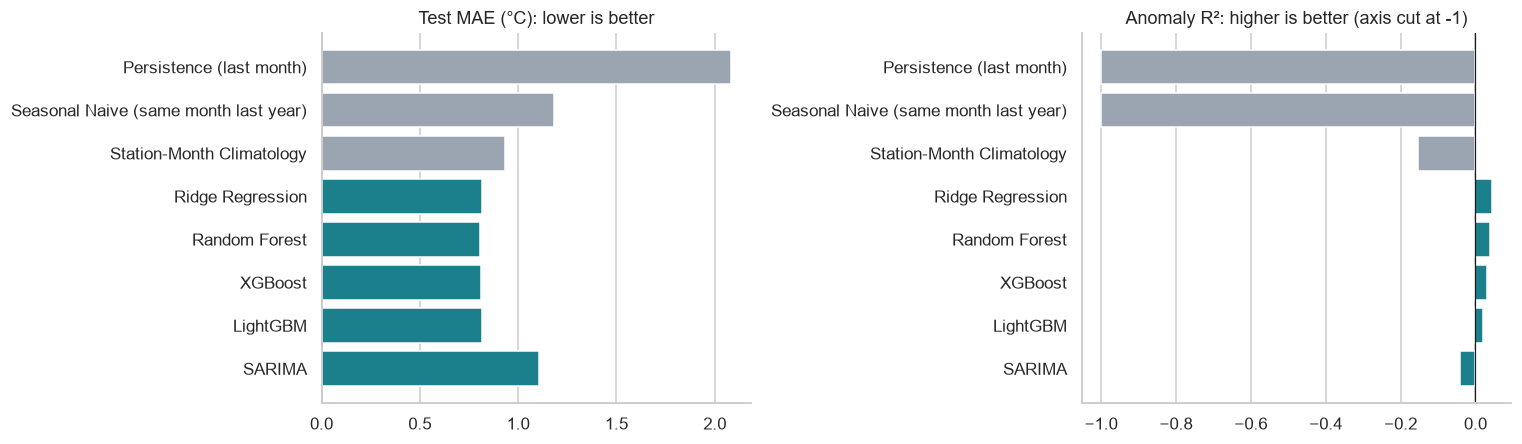

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
cols = ["#9AA5B1" if t == "Baseline" else "#1B7F8C" for t in comp["Model_Type"]]
ax[0].barh(comp.index[::-1], comp["MAE"][::-1], color=cols[::-1]); ax[0].set_title("Test MAE (°C): lower is better")
ax[1].barh(comp.index[::-1], comp["Anomaly_R2"][::-1].clip(lower=-1), color=cols[::-1]); ax[1].set_title("Anomaly R²: higher is better (axis cut at -1)")
ax[1].axvline(0, color="k", lw=.8)
for a in ax: a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

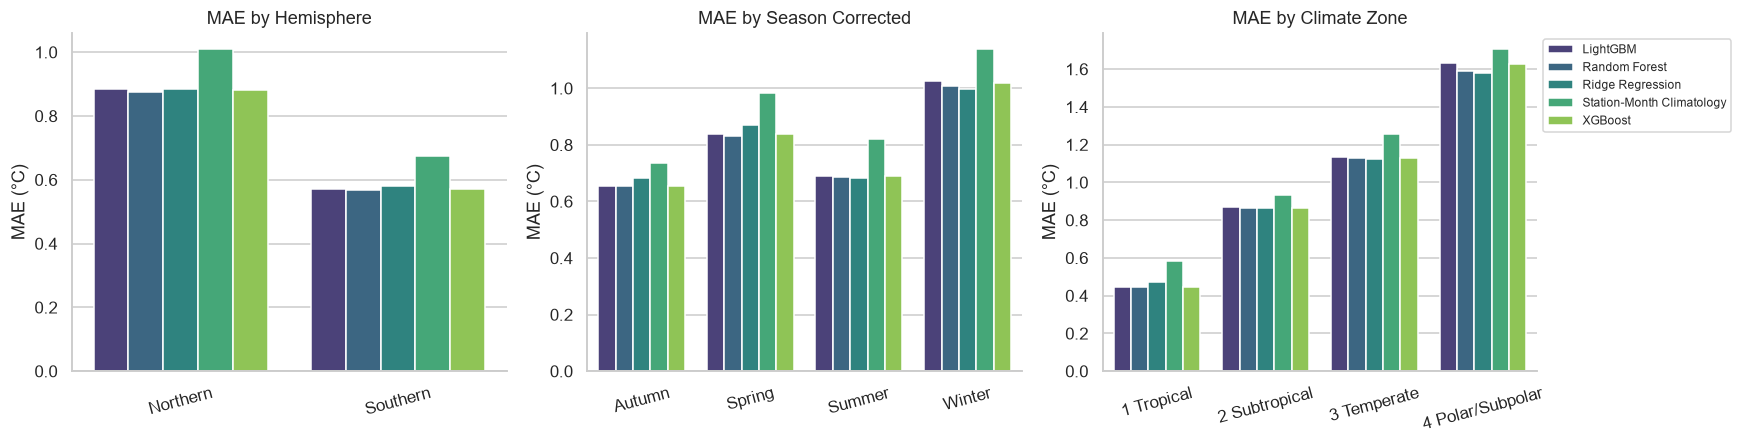

In [34]:
ml_models = ["Station-Month Climatology", "Ridge Regression", "Random Forest", "XGBoost", "LightGBM"]
long = []
for name in ml_models:
    t = te.assign(Model=name, abs_err=(preds_test[name] - te["Average_Temperature_C"]).abs())
    long.append(t[["Model", "Hemisphere", "Season_Corrected", "Climate_Zone", "abs_err"]])
long = pd.concat(long)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col in zip(ax, ["Hemisphere", "Season_Corrected", "Climate_Zone"]):
    g = long.groupby([col, "Model"])["abs_err"].mean().reset_index()
    sns.barplot(data=g, x=col, y="abs_err", hue="Model", ax=a, palette="viridis")
    a.set_ylabel("MAE (°C)"); a.set_title(f"MAE by {col.replace('_', ' ')}"); a.set_xlabel("")
    if a is not ax[2]: a.get_legend().remove()
    a.tick_params(axis="x", rotation=15)
ax[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

Best machine-learning model by test MAE: Random Forest


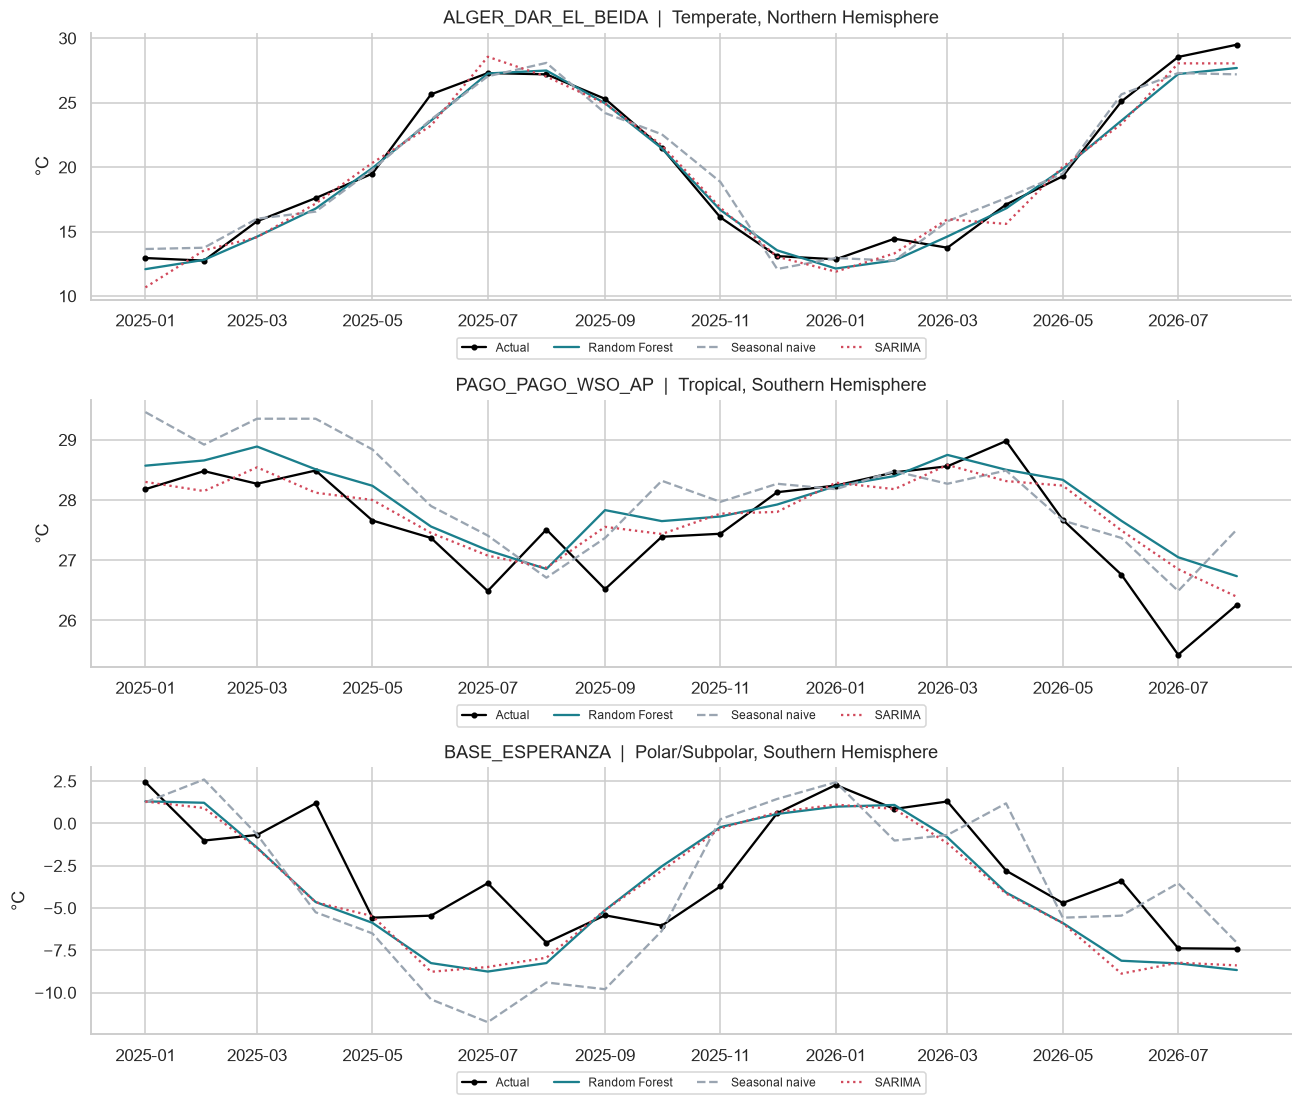

In [36]:
best_ml = comp.loc[comp.Model_Type.isin(["Linear", "Bagging", "Boosting"]), "MAE"].astype(float).idxmin()
print("Best machine-learning model by test MAE:", best_ml)

show = sarima_stations.index[:3] if len(sarima_stations) >= 3 else sarima_stations.index
fig, axes = plt.subplots(len(show), 1, figsize=(12, 3.4 * len(show)), sharex=False)
axes = np.atleast_1d(axes)
for ax_, sid in zip(axes, show):
    s = te[te.Station_ID == sid].sort_values("Date")
    ax_.plot(s["Date"], s["Average_Temperature_C"], "o-", color="black", ms=3, label="Actual")
    ax_.plot(s["Date"], preds_test[best_ml].loc[s.index], color="#1B7F8C", label=best_ml)
    ax_.plot(s["Date"], preds_test["Seasonal Naive (same month last year)"].loc[s.index], "--", color="#9AA5B1", label="Seasonal naive")
    ss = sar[sar.Station_ID == sid].set_index("Date")["pred"].reindex(s["Date"])
    ax_.plot(s["Date"], ss.values, ":", color="#D1495B", label="SARIMA")
    ax_.set_title(f"{stn.loc[sid, 'Name']}  |  {stn.loc[sid, 'Climate_Zone'][2:]}, {stn.loc[sid, 'Hemisphere']} Hemisphere")
    ax_.set_ylabel("°C"); ax_.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

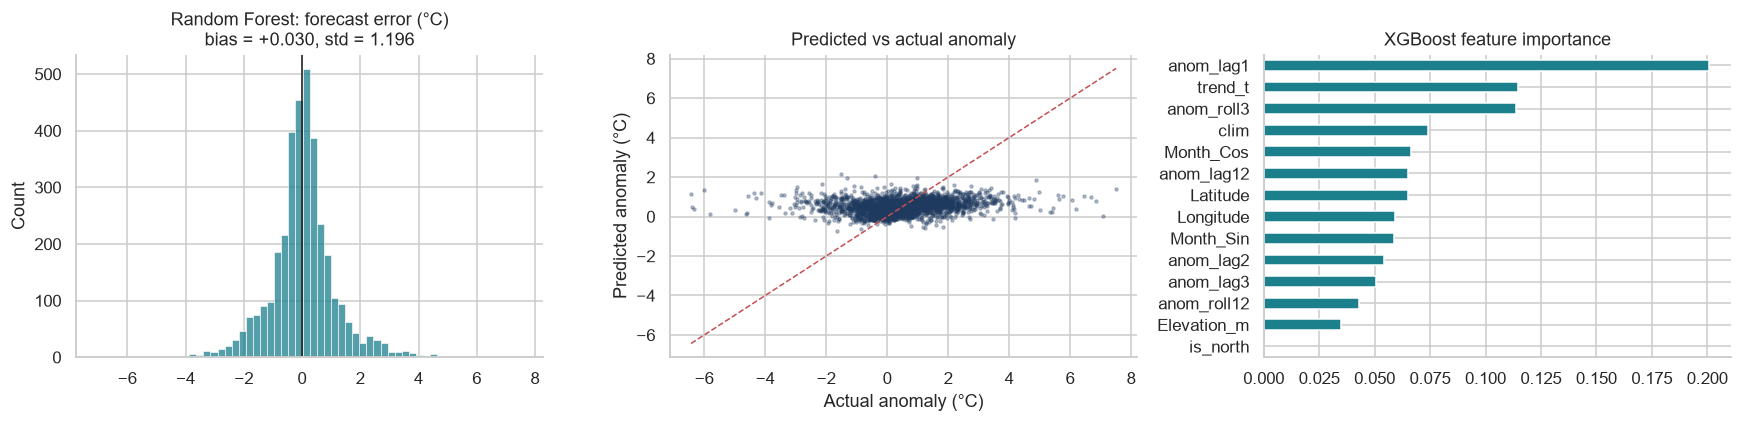

In [38]:
res_best = preds_test[best_ml] - te["Average_Temperature_C"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(res_best, bins=60, ax=ax[0], color="#1B7F8C"); ax[0].axvline(0, color="k", lw=1)
ax[0].set_title(f"{best_ml}: forecast error (°C)\nbias = {res_best.mean():+.3f}, std = {res_best.std():.3f}")
ax[1].scatter(te["anom"], preds_test[best_ml] - te["clim"], s=4, alpha=.3, color="#1F3A5F")
lim = [te["anom"].min(), te["anom"].max()]; ax[1].plot(lim, lim, "r--", lw=1)
ax[1].set_xlabel("Actual anomaly (°C)"); ax[1].set_ylabel("Predicted anomaly (°C)"); ax[1].set_title("Predicted vs actual anomaly")
imp = pd.Series(xgb_final.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=ax[2], color="#1B7F8C"); ax[2].set_title("XGBoost feature importance")
plt.tight_layout(); plt.show()